In [114]:
import pandas as pd
import matplotlib.pyplot as plt

In [115]:
def classify_rtt_bucket(rtt, intervals):
    for low, high in intervals:
        if low <= rtt < high:
            return f"active_transfers_rtt_{low}_{high}"
    return "active_transfers_rtt_other"
def compute_throughput(df, time_points):
    records = []
    for i in range(len(time_points) - 1):
        # window start
        t_start = time_points[i]
        # window ends = start time + 1 min
        t_end = time_points[i + 1]
        # Determine active transfer count: the transfer started at or before t_start, and ends after t_start
        # at the exact time, concurrent transfers
        time_mask = (df['start_dt'] < t_end) & (df['end_dt'] > t_start)
        active = df[time_mask]
        # If no transfers are active in this window, skip it
        if len(active) == 0:
            records.append(0.0)
            continue
        # Compute the throughput within this window
        overlap_start = active['start_dt'].clip(lower=t_start)
        overlap_end = active['end_dt'].clip(upper=t_end)
        # How long this transfer is actually active within the window
        overlap_sec = (overlap_end - overlap_start).dt.total_seconds()
        total_sec = (active['end_dt'] - active['start_dt']).dt.total_seconds()
        bytes_in_window = active['transferred_volume'] * (overlap_sec / total_sec)
        #Assuming a uniform transfer rate, allocate the total volume to this window (and unit calculation)
        records.append(bytes_in_window.sum() / 60 )  # bytes/s
    return records

def compute_active(df, time_points):
    counts = []
    for i in range(len(time_points) - 1):
        t_start = time_points[i]
        t_end = time_points[i + 1]
        # count every transfer that exists at any moment within [t_start, t_end)
        time_mask = (df['start_dt'] < t_end) & (df['end_dt'] > t_start)
        counts.append(int(time_mask.sum()))
    return counts

In [116]:
# FTS transfer records, one row per file transfer. Columns:
#   src_url, dst_url                         - source / destination file URL
#   src_hostname, dst_hostname               - source / destination storage host
#   src_experiment_site, dst_experiment_site - source / destination site (e.g. T2_US_UCSD)
#   activity                                 - FTS activity of the transfer (ASO, Data rebalancing, ...)
#   transferred_volume                       - bytes transferred
#   throughput
#   timestamp_tr_st, timestamp_tr_comp
df_cleaned = pd.read_csv('df_cleaned.csv')

In [117]:
#ddavila: All filters together, bring the ASO filter here
df_cleaned = df_cleaned[df_cleaned['transferred_volume'] != 0]
df_cleaned = df_cleaned[df_cleaned['throughput'] > 0]
df_cleaned = df_cleaned[df_cleaned['activity'] != 'ASO']

#ddavila: can be simplified as :df_cleaned['t_final_transfer_state']="Ok"
#Grace: If it simplified, it will be a series, not df
df_cleaned = df_cleaned[df_cleaned['t_final_transfer_state'].astype(str).str.strip().str.upper() == 'OK']

In [118]:
# Drop duplicate records if any
df_cleaned.drop_duplicates(subset=['transferred_volume', 'timestamp_tr_st', 'dst_url'], keep=False, inplace=True)
# Filter out src is UNKNOWN results
df_cleaned = df_cleaned[df_cleaned['src_experiment_site'] != 'UNKNOWN']

In [119]:
#Top 10 throughput amount
#TOP_N = 10
#site_volume = (df_cleaned.groupby('src_experiment_site')['transferred_volume']
#               .sum().sort_values(ascending=False))
#sites = site_volume.head(TOP_N).index.tolist()
#sites

In [120]:
#top 10 transfer records amount
#TOP_N = 10
#site_count = (df_cleaned.groupby('src_experiment_site')
#              .size().sort_values(ascending=False))
#sites = site_count.head(TOP_N).index.tolist()

In [121]:
sites = [
    "T1_US_FNAL",
    "T2_US_Purdue",
    "T2_US_Vanderbilt",
    "T2_US_Wisconsin",
    "T2_US_MIT",
    "T2_US_Caltech",
    "T2_US_UCSD",
    "T2_US_Florida",
    "T0_CH_CERN",
]

In [122]:
site_clean = df_cleaned.copy()
site_clean.dropna(subset=["src_experiment_site"], inplace=True)
site_clean = site_clean[site_clean["src_experiment_site"].isin(sites)]

In [123]:
site_clean["timestamp_tr_st"] = pd.to_datetime(site_clean["timestamp_tr_st"], unit="ms")
site_clean["timestamp_tr_comp"] = pd.to_datetime(site_clean["timestamp_tr_comp"], unit="ms")
site_clean["start_dt"] = site_clean["timestamp_tr_st"]
site_clean["end_dt"] = site_clean["timestamp_tr_comp"]

# ddavila: Classifies the tx per source site
site_clean["site_bucket"] = site_clean["src_experiment_site"]

#ddavila: the next 2 blocks creates the set of time windows to be used to calculate
# active transfers (1hr) and throughput (1m)
#Get time axis, make the start time floored to the minute, and end time celled to minute.
time_points = pd.date_range(
    start=site_clean['start_dt'].min().floor('min'),
    end=site_clean['end_dt'].max().ceil('min'),
    freq='1min',
)

# hourly time axis for active transfer count
hour_points = pd.date_range(
    start=site_clean['start_dt'].min().floor('10min'),
    end=site_clean['end_dt'].max().ceil('10min'),
    freq='10min',
)

In [124]:
#ddavila: Add comments: calls the functions that calculate active transfers and throughput per site
tp_cols, active_cols = {}, {}
for bucket, g in site_clean.groupby("site_bucket", observed=True):
    tp_cols[bucket] = compute_throughput(g, time_points)
    active_cols[bucket] = compute_active(g, hour_points)

In [125]:
# ddavila: Add comments: creates a new DataFrame based on the dictionaries created above
df_processed = pd.concat(
    {
        "active_transfers": pd.DataFrame(active_cols, index=hour_points[:-1]),
        "throughput": pd.DataFrame(tp_cols, index=time_points[:-1]).resample("10Min").mean(),
    },
    axis=1,
).fillna(0)

In [126]:
# ddavila: Add comments: The next few cells just change the name and order of the columns (formating)
df_processed.columns = [
    f"{metric}_{bucket}"
    for metric, bucket in df_processed.columns
]

In [127]:
# order of sites based on it's throughput
buckets = [s for s in sites if s in active_cols]

In [128]:
ordered_cols = []
for b in buckets:
    ordered_cols += [f"active_transfers_{b}", f"throughput_{b}"]

In [129]:
df_processed = df_processed[ordered_cols]
df_processed[[c for c in ordered_cols if c.startswith("active_transfers_")]] = \
    df_processed[[c for c in ordered_cols if c.startswith("active_transfers_")]].astype(int)

In [130]:
df_processed

,active_transfers_T1_US_FNAL,throughput_T1_US_FNAL,active_transfers_T2_US_Purdue,throughput_T2_US_Purdue,active_transfers_T2_US_Vanderbilt,throughput_T2_US_Vanderbilt,active_transfers_T2_US_Wisconsin,throughput_T2_US_Wisconsin,active_transfers_T2_US_MIT,throughput_T2_US_MIT,active_transfers_T2_US_Caltech,throughput_T2_US_Caltech,active_transfers_T2_US_UCSD,throughput_T2_US_UCSD,active_transfers_T2_US_Florida,throughput_T2_US_Florida,active_transfers_T0_CH_CERN,throughput_T0_CH_CERN
2026-09-01 00:00:00,1,6.024454e+06,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000,0,0.000000e+00,0,0.000000e+00,2,5.033228e+06
2026-09-01 00:10:00,6,9.419992e+06,1,8.597900e+03,0,0.000000e+00,3,4.996431e+05,1,8.937470e+03,1,143332.723333,1,1.337638e+04,0,0.000000e+00,4,1.205703e+07
2026-09-01 00:20:00,2,9.280979e+04,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000,0,0.000000e+00,0,0.000000e+00,4,1.739589e+07
2026-09-01 00:30:00,10,1.469730e+07,0,0.000000e+00,0,0.000000e+00,4,8.675150e+06,1,2.322946e+05,1,10766.253333,1,1.760059e+04,0,0.000000e+00,9,3.257089e+07
2026-09-01 00:40:00,4,1.045385e+07,0,0.000000e+00,0,0.000000e+00,1,2.449431e+04,1,3.460163e+06,0,0.000000,0,0.000000e+00,0,0.000000e+00,4,1.069749e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-07 23:10:00,4,1.782602e+07,3,1.137425e+07,0,0.000000e+00,2,7.245841e+06,0,0.000000e+00,0,0.000000,1,4.306309e+06,0,0.000000e+00,3,2.017601e+07
2026-09-07 23:20:00,2,1.323200e+07,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000,0,0.000000e+00,0,0.000000e+00,1,5.886401e+06
2026-09-07 23:30:00,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000,1,3.726973e+06,0,0.000000e+00,2,8.520776e+06
2026-09-07 23:40:00,2,1.070913e+07,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000e+00,0,0.000000,2,7.860351e+06,1,4.068116e+06,10,5.534908e+07


In [131]:
# Add the total throughput column
df_throughput = pd.Series(compute_throughput(site_clean, time_points), index=time_points[:-1]).resample("10Min").mean()
df_model_data = df_processed.join(df_throughput.rename("total_throughput"))

In [132]:
feature_cols = [c for c in df_model_data.columns if c.startswith("active_transfers_")]

X = df_model_data[feature_cols]
y = df_model_data["total_throughput"]

mask = y.notna() & (y > 0)
X, y = X[mask], y[mask]

In [133]:
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error
kf = KFold(n_splits=8, shuffle=True, random_state=42)
results, weights_per_fold = [], []

for i, (tr_i, te_i) in enumerate(kf.split(df_model_data)):
    train, test = df_model_data.iloc[tr_i], df_model_data.iloc[te_i]

    # guard: a site with no active transfers in this fold gets weight 0 (avoid division by zero)
    w = pd.Series({b: (train[f"throughput_{b}"].sum() / train[f"active_transfers_{b}"].sum()
                       if train[f"active_transfers_{b}"].sum() > 0 else 0.0)
                for b in buckets})
    weights_per_fold.append(w.rename(f"fold_{i}"))

    y_hat = sum(test[f"active_transfers_{b}"] * w[b] for b in buckets)
    y_t = test["total_throughput"]
    results.append({"fold": i, "R2": r2_score(y_t, y_hat),
                    "WAPE": (y_hat - y_t).abs().sum() / y_t.sum()})

print(pd.DataFrame(results).set_index("fold").round(3))

         R2   WAPE
fold              
0     0.942  0.184
1     0.852  0.197
2     0.918  0.207
3     0.876  0.204
4     0.923  0.167
5     0.891  0.213
6     0.940  0.155
7     0.877  0.192


In [134]:
wdf_clean = pd.concat(weights_per_fold, axis=1)

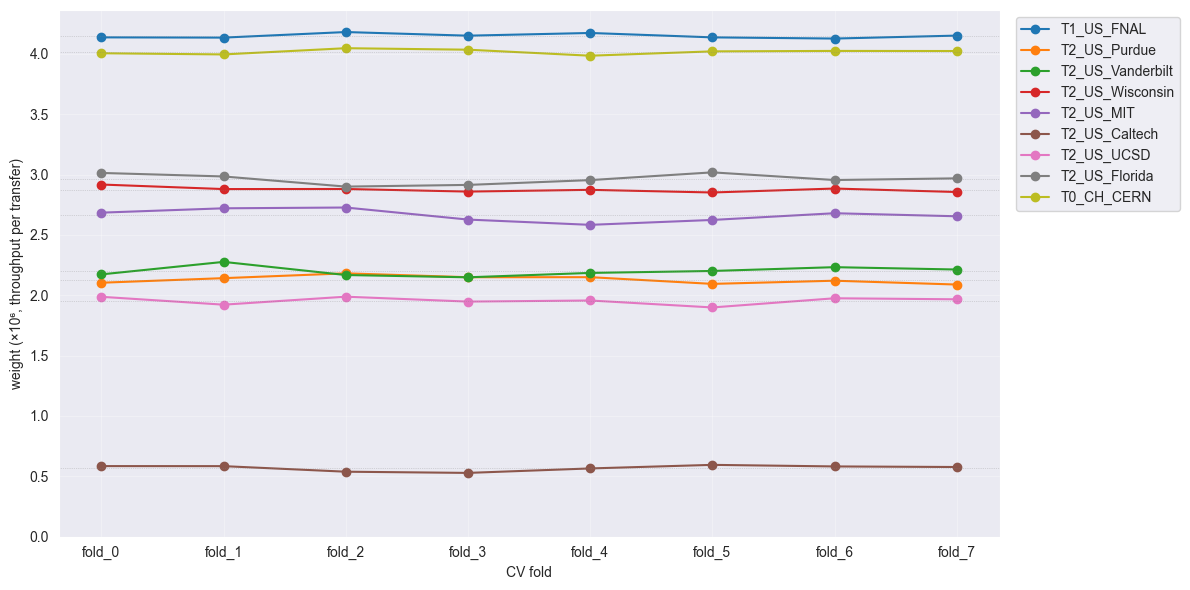

In [135]:
#Proof of weight is almost constant
fig, ax = plt.subplots(figsize=(12, 6))

for b in wdf_clean.index:
    ax.plot(wdf_clean.columns, wdf_clean.loc[b] / 1e6, marker="o", label=b, linewidth=1.5)
    ax.axhline(wdf_clean.loc[b].mean() / 1e6, color="gray", linewidth=0.5,
               linestyle=":", alpha=0.5)

ax.set_ylim(0, None)
ax.set_xlabel("CV fold")
ax.set_ylabel("weight (×10⁶, throughput per transfer)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()